# Control

Continuous plants with discrete controllers: a DC motor under PI speed
control, with a voltage limit and anti-windup, and a pendulum on a cart
balanced by LQR. Plants are `ContinuousLTI` (exact for held inputs) or
`ODE`; loops through them need no extra delay and compile with numba. Each
loop is checked against the discrete theory.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import scipy.signal as sig
from scipy.linalg import solve_continuous_are

import sigline as sl

## 1. A DC motor

Armature voltage $v$, resistance $R$, inductance $L$, torque constant $K$,
inertia $J$, friction $b$: from voltage to speed
$G(s) = K / ((Js + b)(Ls + R) + K^2)$, with an electrical (0.5 ms) and a
mechanical ($\tau_m = JR/K^2$ = 8 ms) time constant. `ContinuousLTI` holds
each input over a sample and integrates exactly; SciPy's ZOH
discretisation is the reference.

In [2]:
R, L, K, J, b = 1.0, 0.5e-3, 0.05, 2e-5, 1e-5  # ohm, henry, N m/A, kg m^2, N m s
num, den = [K], [J * L, J * R + b * L, b * R + K**2]
fs = 10e3
T, tau_m = 1 / fs, J * R / K**2
nd, dd, _ = sig.cont2discrete((num, den), T, "zoh")
nd = np.squeeze(nd)

motor, speed = sl.ContinuousLTI(num, den, name="motor"), sl.Scope("speed")
sl.Step(0.0, name="1 V") >> motor >> speed
d = sl.Diagram(speed, fs=fs)
d.run(0.05)
ref = sig.lfilter(nd, dd, np.ones(d.n))
print(f"max |error| vs scipy zoh: {np.max(np.abs(speed.data - ref)):.1e} rad/s")

max |error| vs scipy zoh: 5.0e-13 rad/s


## 2. PI speed control

The PI controller $u[n] = k_p e[n] + k_i T \sum_{m \le n} e[m]$ is an `IIR`;
$k_i = k_p / \tau_m$ cancels the mechanical pole. A `for` loop over $k_p$
compares each step response with the closed loop $T(z) = CP/(1 + CP)$ and
reads the phase margin from the loop gain $L(z) = C(z)P(z)$: less margin,
more overshoot.

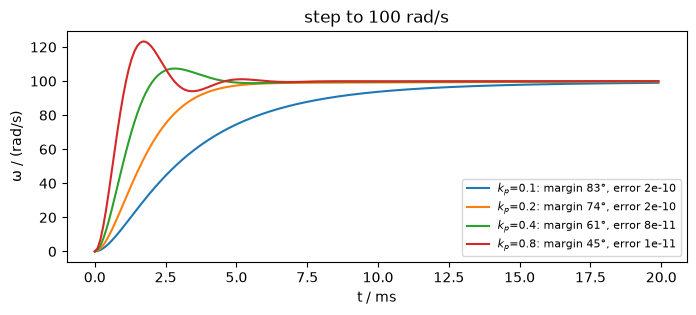

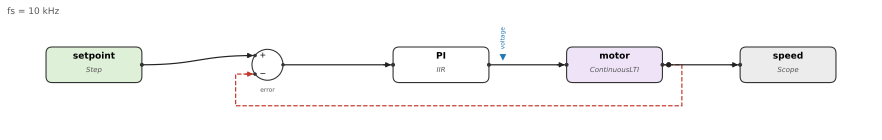

In [3]:
def speed_loop(controller, setpoint=100.0):
    ref, err = sl.Step(0.0, after=setpoint, name="setpoint"), sl.Sum("+-", name="error")
    plant, w = sl.ContinuousLTI(num, den, name="motor"), sl.Scope("speed")
    ref >> err["x0"]
    err >> controller >> plant >> w
    plant >> err["x1"]
    d = sl.Diagram(w, fs=fs)
    return d, w, d.probe(controller, name="voltage")


def pi(kp):
    return sl.IIR(b=[kp + kp / tau_m * T, -kp], a=[1.0, -1.0], name="PI")


def theory(kp, n, setpoint=100.0):
    c_b, c_a = [kp + kp / tau_m * T, -kp], [1.0, -1.0]
    lb, la = np.convolve(c_b, nd), np.convolve(c_a, dd)
    f = np.logspace(0, np.log10(fs / 2), 4000)
    loop = sig.freqz(lb, la, worN=f, fs=fs)[1]
    i = np.argmin(np.abs(np.abs(loop) - 1))
    margin = 180 + np.degrees(np.angle(loop[i]))
    return sig.lfilter(lb, la + lb, setpoint * np.ones(n)), margin


fig, ax = plt.subplots(figsize=(8, 3))
for kp in (0.1, 0.2, 0.4, 0.8):
    d, w, u = speed_loop(pi(kp))
    d.run(0.02)
    step, margin = theory(kp, d.n)
    err = np.max(np.abs(w.data - step))
    ax.plot(
        1e3 * d.t, w.data, label=f"$k_p$={kp}: margin {margin:.0f}°, error {err:.0e}"
    )
ax.set(xlabel="t / ms", ylabel="ω / (rad/s)", title="step to 100 rad/s")
ax.legend(fontsize=8)
plt.show()
d

## 3. A voltage limit and anti-windup

The driver gives at most 12 V. A step to 200 rad/s asks for 40 V at first:
the voltage saturates while the integrator keeps summing the large error,
and the speed overshoots. Clamping stops the integrator while the output is
limited, a few lines of scalar Python: a `FuncSingle` with the integral as
its state. Unsaturated, it equals the `IIR`.

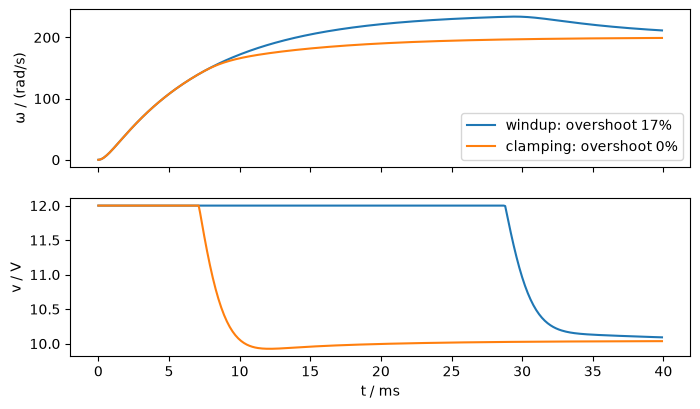

unsaturated: max |IIR - FuncSingle| = 4.3e-14


In [4]:
kp, umax = 0.2, 12.0


def pi_clamped(e, s, kp=kp, ki=kp / tau_m, T=T, umax=umax):
    s_new = s + ki * T * e
    u = kp * e + s_new
    if u > umax:
        return umax, s  # saturated: keep the integral
    if u < -umax:
        return -umax, s
    return u, s_new


limited = pi(kp)
windup = sl.Subsystem(
    inputs={"x": limited},
    outputs={"y": limited >> sl.FuncChunk(lambda u, m=umax: np.clip(u, -m, m))},
    name="PI, limited",
)
fig, (a1, a2) = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True)
for name, ctrl in (
    ("windup", windup),
    ("clamping", sl.FuncSingle(pi_clamped, state=0.0)),
):
    d, w, u = speed_loop(ctrl, setpoint=200.0)
    d.run(0.04)
    a1.plot(
        1e3 * d.t,
        w.data,
        label=f"{name}: overshoot {max(w.data.max() / 200 - 1, 0):.0%}",
    )
    a2.plot(1e3 * d.t, u.data)
a1.set(ylabel="ω / (rad/s)")
a1.legend()
a2.set(xlabel="t / ms", ylabel="v / V")
plt.show()

d1, w1, _ = speed_loop(pi(kp))
d2, w2, _ = speed_loop(sl.FuncSingle(pi_clamped, state=0.0, params={"umax": 1e9}))
d1.run(0.02)
d2.run(0.02)
print(f"unsaturated: max |IIR - FuncSingle| = {np.max(np.abs(w1.data - w2.data)):.1e}")

## 4. Balancing a pendulum on a cart

Cart mass $M$ at position $p$, a point mass $m$ on a light rod of length
$l$ (`ell`) at angle $\theta$ from upright, force $F$ on the cart:

$$\ddot p = \frac{F + m \sin\theta\,(l\dot\theta^2 - g\cos\theta)}{M + m\sin^2\theta},
\qquad \ddot\theta = \frac{g \sin\theta - \ddot p \cos\theta}{l}.$$

Linearised at $\theta = 0$, $\dot x = Ax + BF$ for $x = (p, \dot p, \theta,
\dot\theta)$, and LQR gives the state feedback $F = -K(x - x_\mathrm{target})$.
The plant is an `ODE` with fixed-step RK4; the controller a matrix product.
State vectors run in Python inside loops, so `compile_loops="python"`.

K = [-10.   -11.66 -73.54 -14.83]


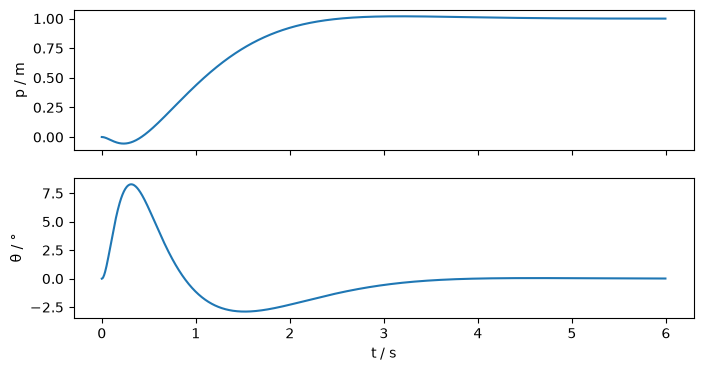

to go right the cart first moves left: lowest -5.5 cm


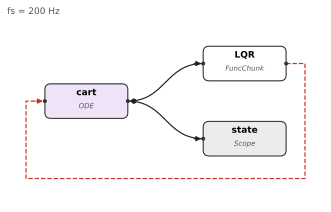

In [5]:
M, m, ell, g = 1.0, 0.2, 0.5, 9.81


def cart(t, x, F):
    p, v, th, w = x
    s, c = np.sin(th), np.cos(th)
    a = (F + m * s * (ell * w**2 - g * c)) / (M + m * s**2)
    return [v, a, w, (g * s - a * c) / ell]


A = np.array(
    [
        [0, 1, 0, 0],
        [0, 0, -m * g / M, 0],
        [0, 0, 0, 1],
        [0, 0, (M + m) * g / (M * ell), 0],
    ]
)
B = np.array([[0.0], [1 / M], [0.0], [-1 / (M * ell)]])
Rw = 0.1
K_lqr = (
    B.T @ solve_continuous_are(A, B, np.diag([10.0, 1, 100, 1]), [[Rw]]) / Rw
).ravel()
print("K =", np.round(K_lqr, 2))


def pendulum(theta0_deg, target=0.0, rate=200.0, T=5.0):
    x0 = [0.0, 0.0, np.radians(theta0_deg), 0.0]
    plant = sl.ODE(cart, x0, inputs=("F",), method="RK4", name="cart")
    lqr = sl.FuncChunk(
        lambda x, K=K_lqr, p=target: -((x - [p, 0, 0, 0]) @ K), name="LQR"
    )
    state = sl.Scope("state")
    plant >> lqr >> plant
    plant >> state
    d = sl.Diagram(state, fs=rate, compile_loops="python")
    d.run(T)
    return d, state.data


d, x = pendulum(0.0, target=1.0, T=6.0)
fig, ax = plt.subplots(2, 1, figsize=(8, 4), sharex=True)
ax[0].plot(d.t, x[:, 0])
ax[0].set(ylabel="p / m")
ax[1].plot(d.t, np.degrees(x[:, 2]))
ax[1].set(xlabel="t / s", ylabel="θ / °")
plt.show()
print(f"to go right the cart first moves left: lowest {100 * x[:, 0].min():.1f} cm")
d

From a tilt, the prediction is the linear plant held per sample under the
same feedback, $x[n+1] = (A_d - B_d K) x[n]$. It holds for small angles;
at larger ones the sine and cosine tell. Slower control holds each force
longer: the loop fails once an eigenvalue of $A_d - B_dK$ leaves the unit
circle, which the simulation confirms (a diverging run ends in the check
for inf).

In [6]:
def linear_prediction(theta0_deg, rate, n):
    Ad, Bd, *_ = sig.cont2discrete((A, B, np.eye(4), np.zeros((4, 1))), 1 / rate, "zoh")
    x = np.empty((n, 4))
    x[0] = [0, 0, np.radians(theta0_deg), 0]
    for k in range(1, n):
        x[k] = (Ad - Bd * K_lqr) @ x[k - 1]
    return x, np.max(np.abs(np.linalg.eigvals(Ad - Bd * K_lqr)))


for theta0 in (1.0, 10.0, 25.0):
    d, x = pendulum(theta0)
    lin, _ = linear_prediction(theta0, 200.0, len(x))
    err = np.degrees(np.max(np.abs(lin[:, 2] - x[:, 2])))
    print(f"from {theta0:4.0f}°: max |linear - ODE| = {err:.1e}°")

for rate in (50.0, 10.0, 7.0):
    _, rho = linear_prediction(5.0, rate, 2)
    try:
        with np.errstate(all="ignore"):
            d, x = pendulum(5.0, rate=rate)
        result = "balanced" if abs(x[-1, 2]) < np.radians(0.5) else "not balanced"
    except FloatingPointError:
        result = "diverged"
    print(f"{rate:4.0f} Hz: max |eig| = {rho:.3f}, simulated: {result}")

from    1°: max |linear - ODE| = 9.5e-05°


from   10°: max |linear - ODE| = 9.7e-02°


from   25°: max |linear - ODE| = 1.6e+00°
  50 Hz: max |eig| = 0.974, simulated: balanced
  10 Hz: max |eig| = 0.878, simulated: balanced
   7 Hz: max |eig| = 1.845, simulated: diverged


## Summary

- Plants: `ContinuousLTI` (exact for held inputs) or `ODE`; controllers:
  `IIR`, `FuncChunk`, or `FuncSingle` for logic such as anti-windup.
- Loops need no extra delay, compile with numba, and match the discrete
  theory; limits, gains and sample rates are a `for` loop away.